# Held-out test: does T3 + prior correction (λ = 1) beat Ramen on ImageNet-R / -A / -Sketch?

**Question.** T3 + pc(λ = 1) was assembled on ImageNet-C and DomainNet (λ = 1 picked post-hoc there), then frozen and checked not to break CIFAR / EuroSAT. Does it beat Ramen on data none of its settings were tuned on?

**Hypothesis (pre-registered, `PREREGISTRATION.md`, written before any model saw these images).** Mean gain of T3 + pc(λ = 1) over Ramen, domain-averaged, seeds 0–4, is above the noise floor of this stream.

**Variants** (true labels are used only for scoring):

| Name | Role | What it is |
|---|---|---|
| NoAdapt | reference | CLIP ViT-B/16 zero-shot, default 7-prompt ensemble |
| Ramen | baseline | `cfg/ImageNetVariants/Ramen.yaml` = ImageNet-C config (capacity 75, topk 1, β 0, signSGD lr 0.01) |
| T3 + pc(lam=1) | **primary** | RamenActive `active_set: prob`, `temperature: 3`, then logit − 1·log(π_t / uniform), π_t = EMA (m = 0.99) of the predicted class marginal |
| T3, Ramen + pc(lam=1) | secondary | the two halves of the primary |
| T3 + pc(lam=2), pc(lam=0.5), knn variants | **post-hoc** | for context only |

**Data.** One shuffled mixed stream, batches of 100, over **all 1,000 ImageNet classes**: ImageNet-R (30,000 renditions, 200 classes present), ImageNet-A (7,500 natural adversarial photos, 200 classes), ImageNet-Sketch (50,889 sketches, 1,000 classes). Labels are remapped from WordNet ids to the ImageNet-1k index. Because of the 1,000-way head, R / A accuracies are **not comparable** to the usual 200-class numbers in the literature. Downloads were verified by size, by SHA-256 (Sketch), and by image counts.

**Seeds.** 0–4: stream order and Ramen's selection randomness; images identical. NoAdapt is stateless (seed 0 only).

**How the runs were produced.** `bash run_queue.sh` (detached, one worker per GPU) runs `run_heldout.py <seed> <run>` with probabilities saved. Then `python heldout_analysis.py` → `results/heldout/*.csv`.

**What counts as a result.** Primary mean gain > noise floor = 2 × (max − min) of Ramen's domain-averaged accuracy over seeds 0–4 on this stream (computed below).

**Sections.** 1 Setup · 2 Data · 3 Sanity checks · 4 Primary result · 5 Secondary and post-hoc · 6 Per domain · 7 Interpretation · 8 Glossary

## 1. Setup

In [1]:
import os, sys
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '')
sys.path.insert(0, '..'); sys.path.insert(0, '../2026-10-25_stacking')
import pandas as pd
import stack, heldout_analysis as ha
pd.set_option('display.width', 200)
t = ha.load(); FLOOR, ACCS = ha.noise_floor()
stack.NOISE_FLOOR[ha.DS] = round(FLOOR, 2)
sorted(t.seed.unique())

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

## 2. The data the code ran on

In [2]:
stack.data_table([ha.DS])

,ImageNet-R/A/Sketch
model,clip_vitbase16
images,"88,389"
domains,3
images per domain,"7,500 to 50,889"
classes,1000
batches of 100,884
NoAdapt correct,"44,942 of 88,389 (50.8%)"
Ramen correct (seed 0),"46,402 of 88,389 (52.5%)"
NoAdapt acc (domain-avg),46.36
"Ramen acc (domain-avg, seed 0)",47.86


In [3]:
z = pd.read_pickle(stack.path(ha.DS, 0, 'NoAdapt') + '.pkl')
pd.DataFrame({'images': z.groupby('domain', observed=True).size(),
              'classes present': z.groupby('domain', observed=True).label.nunique(),
              'NoAdapt correct': z.groupby('domain', observed=True).correct.sum(),
              'NoAdapt acc %': (z.groupby('domain', observed=True).correct.mean() * 100).round(2)})

,images,classes present,NoAdapt correct,NoAdapt acc %
domain,,,,
rendition,30000,200,17998,59.99
adversarial,7500,200,2299,30.65
sketch,50889,1000,24645,48.43


In [4]:
pd.Series({**{f'Ramen seed {s}': round(a, 3) for s, a in enumerate(ACCS)}, 'range': round(max(ACCS) - min(ACCS), 3), 'noise floor (2 x range)': round(FLOOR, 3)})

Ramen seed 0               47.863
Ramen seed 1               47.932
Ramen seed 2               47.875
Ramen seed 3               47.690
Ramen seed 4               47.855
range                       0.242
noise floor (2 x range)     0.483
dtype: float64

## 3. Sanity checks

- **Labels.** Zero-shot accuracy on Sketch (1,000 classes, the standard setting) should be close to the published ~46–48% for CLIP ViT-B/16 (table above). Wrong label remapping would show as near-chance accuracy.
- **Saved probabilities.** Every loaded run asserts that the argmax of its saved softmax equals its saved predictions (`stack.load`).
- **Stream alignment.** Ramen and T3 of the same seed see the identical stream order (asserted in `stack.stack_seed`).

## 4. Primary result (pre-registered)

In [5]:
ha.verdict(t, FLOOR)

{'primary': 'T3 + pc(lam=1)',
 'mean gain': np.float64(-1.147),
 'std': np.float64(0.089),
 'noise floor': np.float64(0.483),
 'seeds above floor': '0/5',
 'claim holds': False}

In [6]:
s = ha.summary(t, FLOOR)
s.astype({'gain mean': float, 'gain std': float, 'gain min': float, 'images vs Ramen': float}).round(2)

,role,gain mean,gain std,gain min,positive,above floor,CI excludes 0,images vs Ramen
T3 + pc(lam=1),primary,-1.15,0.09,-1.23,0/5,0/5,0/5,-527.6
T3,secondary,0.59,0.04,0.56,5/5,5/5,5/5,300.6
Ramen + pc(lam=1),secondary,-2.58,0.10,-2.67,0/5,0/5,0/5,-1293.0
T3 + pc(lam=2),post-hoc,-3.90,0.12,-4.04,0/5,0/5,0/5,-2368.2
T3 + pc(lam=0.5),post-hoc,-0.13,0.10,-0.28,0/5,0/5,0/5,-6.6
Ramen + knn,post-hoc,0.43,0.12,0.27,5/5,2/5,5/5,359.0
T3 + knn + pc(lam=1),post-hoc,-2.56,0.09,-2.68,0/5,0/5,0/5,-1046.6


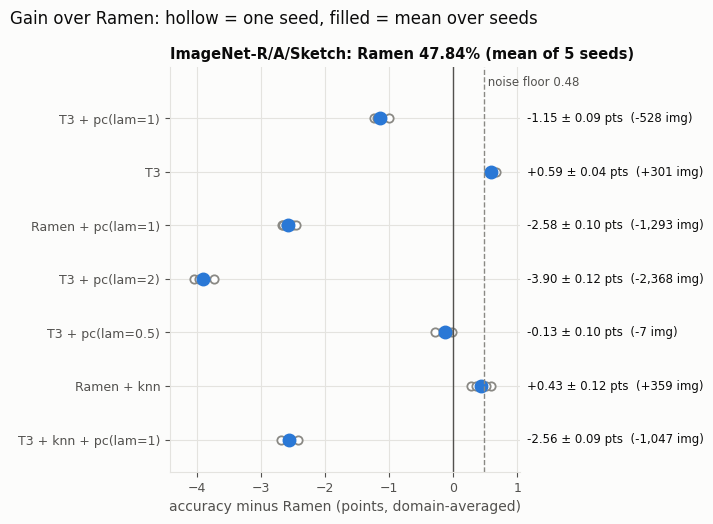

In [7]:
fig = stack.plot_seed_gains({ha.DS: t}, variants=ha.SHOW)

## 5. Secondary: every method vs zero-shot, and where the gain comes from

In [8]:
ha.vs_noadapt(t).round(2)

,acc (domain-avg),vs NoAdapt
NoAdapt,46.36,0.00
Ramen,47.84,1.48
T3,48.44,2.08
Ramen + pc(lam=1),45.27,-1.09
T3 + pc(lam=1),46.70,0.34


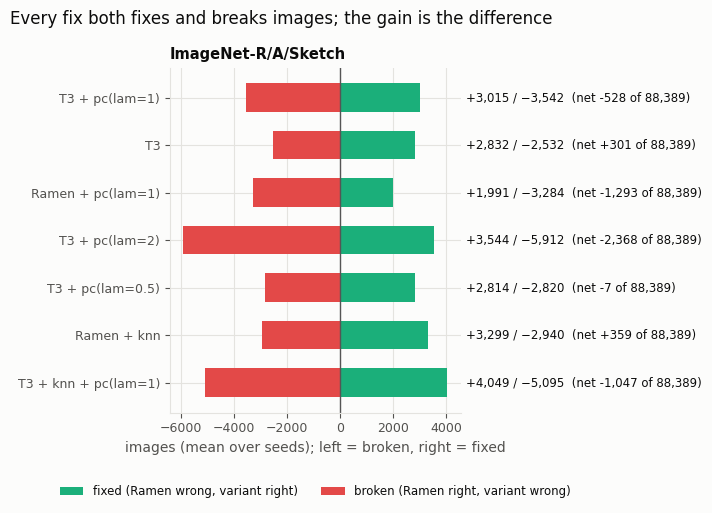

In [9]:
fig = stack.plot_fixed_broken({ha.DS: t}, variants=ha.SHOW)

## 6. Per domain

Gain over Ramen per domain (points, mean over seeds).

In [10]:
pdm = ha.load('per_domain')
pdm[pdm.variant.isin(ha.SHOW)].groupby(['domain', 'variant']).gain.mean().unstack()[ha.SHOW].round(2)

variant,T3 + pc(lam=1),T3,Ramen + pc(lam=1),T3 + pc(lam=2),T3 + pc(lam=0.5),Ramen + knn,T3 + knn + pc(lam=1)
domain,,,,,,,
adversarial,-1.00,1.37,-3.44,-3.89,0.36,0.18,-4.03
rendition,-3.78,0.06,-5.51,-9.10,-1.67,1.07,-5.32
sketch,1.34,0.36,1.21,1.28,0.92,0.05,1.68


### Why prior correction fails here

Labels are used only to describe what happened. The 314 classes of ImageNet-R ∪ ImageNet-A carry most images, so the true class marginal is far from uniform. Prior correction pulls predictions toward uniform, away from those classes.

In [11]:
import numpy as np
df, P = stack.load(ha.DS, 0, 'Ramen'); _, T = stack.load(ha.DS, 0, 'active_prob_T3')
y = df.label.values; N = len(y)
ra = np.zeros(1000, bool); ra[np.unique(y[df.domain.astype(str).values != 'sketch'])] = True
true = np.bincount(y, minlength=1000) / N
z5 = pd.read_pickle(stack.path('ImageNetC5K', 0, 'NoAdapt') + '.pkl'); t5 = np.bincount(z5.label, minlength=1000) / len(z5)
print(f'R/A classes: {ra.sum()}; images with an R/A label: {stack.fmt(int(ra[y].sum()), N)}')
print(f'TV(true marginal, uniform): {0.5 * np.abs(true - 1e-3).sum():.3f} here vs {0.5 * np.abs(t5 - 1e-3).sum():.3f} on ImageNet-C 5K')
rows = {}
for name, X in [('Ramen', P), ('T3', T)]:
    for lam in (0, 1.0):
        pred = X.argmax(1) if lam == 0 else stack.prior_correct(X, df.batch.values, lam)
        rows[name + ('' if lam == 0 else ' + pc(lam=1)')] = {
            'predictions on R/A classes': stack.fmt(int(ra[pred].sum()), N),
            'wrong predictions into Sketch-only classes': f'{int(((pred != y) & ~ra[pred]).sum()):,}',
            'pooled acc %': round((pred == y).mean() * 100, 2)}
pd.DataFrame(rows).T  # seed 0; true share of R/A labels is 60.5%

R/A classes: 314; images with an R/A label: 53,453 of 88,389 (60.5%)
TV(true marginal, uniform): 0.311 here vs 0.167 on ImageNet-C 5K


,predictions on R/A classes,wrong predictions into Sketch-only classes,pooled acc %
Ramen,"43,330 of 88,389 (49.0%)","29,686",52.5
Ramen + pc(lam=1),"39,113 of 88,389 (44.3%)","33,123",50.94
T3,"43,529 of 88,389 (49.2%)","29,389",52.84
T3 + pc(lam=1),"40,330 of 88,389 (45.6%)","31,961",51.86


## 7. Interpretation

**The pre-registered claim fails.** T3 + pc(λ = 1) is **−1.15 ± 0.09** pts against Ramen (below Ramen on 5/5 seeds, every per-seed CI below zero; floor 0.48). The prior correction breaks it: Ramen + pc(λ = 1) alone is −2.58 ± 0.10.

**T3 alone is confirmed on held-out data:** **+0.59 ± 0.04**, above the floor on 5/5 seeds (min +0.56), every per-seed CI excluding zero. This is the first time a change carried over to a dataset it was never tuned on and cleared the floor on every seed. T3 = 48.44% vs Ramen 47.84% vs NoAdapt 46.36% (domain-averaged).

**Why prior correction fails here: the uniform target points the wrong way.**
- 314 of the 1,000 classes (those of ImageNet-R ∪ ImageNet-A) carry 53,453 of 88,389 images (60.5%). The true class marginal is far from uniform: its total-variation distance from uniform is 0.31, against 0.17 on ImageNet-C 5K.
- Ramen already under-predicts those classes: 49.0% of its predictions vs 60.5% true (seed 0). Correcting toward uniform pushes it further the wrong way, to 44.3%, and sends 3,437 more wrong predictions into Sketch-only classes (29,686 → 33,123).
- So pc helps only when the label marginal is close to uniform. That held on CIFAR, EuroSAT and roughly on ImageNet-C 5K, but not here or on DomainNet at λ = 2. Its gains on the earlier datasets partly reflected their near-uniform marginals, not a general property.

**Post-hoc (context only):** every λ hurts here (λ = 0.5: −0.13, λ = 2: −3.90). kNN smoothing on Ramen gives +0.43 ± 0.12 (5/5 positive, 2/5 above the floor), but stacking it with pc(λ = 1) on T3 is −2.56.

**Caveats.** The 1,000-way label space is a design choice (fixed in advance). Under each dataset's own 200-class head the marginal would be closer to uniform and pc might behave differently. That is untested, and testing it now would be post-hoc.

**What this changes.**
1. T3 is the one held-out-confirmed improvement: ImageNet-C +0.62, DomainNet +0.24, ImageNet-R/A/Sketch +0.59, each on 5/5 seeds.
2. Prior correction with a uniform target should not be part of the method. The open question is whether an *estimated* target fixes it: EM label-shift estimation, compared against an oracle true-marginal ceiling. This stream, with its strongly non-uniform marginal, is now the natural stress test. Any result on it would be post-hoc for this dataset.


## 8. Glossary

| Term | Meaning |
|---|---|
| Ramen | CLIP zero-shot + per-class memory of (feature, entropy gradient); one signSGD step per batch from retrieved entries, predict, reset |
| T3 | zero-shot-weighted active set: each class queue's vote weighted by the query's zero-shot probability at temperature 3 |
| pc (prior correction) | subtract λ·log(estimated predicted-class share / uniform) from the logits |
| knn | 50/50 mix of a prediction with the predictions on the 10 most similar earlier images (post-hoc here) |
| held-out | a dataset on which no setting was chosen |
| pre-registered | the setting, metric and decision rule were written down before the data was run |
| noise floor | 2 × (max − min) of Ramen's accuracy over seeds 0–4 |
| domain-averaged accuracy | mean of the three per-domain accuracies (ImageNet-A, the smallest domain, counts as much as Sketch) |
| fixed / broken vs Ramen | images Ramen gets wrong that the variant gets right / and the reverse |
| cluster bootstrap CI | 95% interval from resampling images (Poisson weights), per seed |